# Plasma Na: posterior contrasts

Vehicle and Empa − Vehicle are fitted as separate models. Effects are averaged equally over the other genotype, age, and sex levels. Posterior intervals and sign probabilities are computed from posterior draws.

The source notebook uses `Intercept`, `gtyp`, `age`, `sex`, `gtyp:age`, and `gtyp:sex` in both models, matching `kidney.contrasts.get_t_groups`.

In [1]:
import arviz as az
import pandas as pd
import matplotlib.pyplot as plt

from kidney.paths import RESULTS_DIR, PLOT_DIR
from kidney.plotting import forestplot_oz
from kidney.sign_probs import get_sign_probs, get_signif
from kidney.contrasts import (
    get_t_groups,
    get_overall_effects,
    get_gtyp_given_sex_age,
    get_sex_given_gtyp_age,
)

plt.rcParams['pdf.fonttype'] = 42
az.rcParams['data.load'] = 'eager' 

In [2]:
idata_vehicle = az.from_netcdf(RESULTS_DIR / "idata_plasma_na_vehicle.nc")
idata_change = az.from_netcdf(RESULTS_DIR / "idata_plasma_na_empa_minus_vehicle.nc")

required = {"gtyp", "age", "sex", "gtyp:age", "gtyp:sex"}
for name, idata in (("Vehicle", idata_vehicle), ("Empa - Vehicle", idata_change)):
    missing = required - set(idata.posterior.data_vars)
    if missing:
        raise ValueError(f"{name}: missing model coefficients {sorted(missing)}")
    for term in required:
        dims = [d for d in idata.posterior[term].dims if d not in ("chain", "draw")]
        if len(dims) != 1 or idata.posterior[term].sizes[dims[0]] != 1:
            raise ValueError(f"{name}: {term} is not a single coefficient: {dims}")

print("Model coefficients verified for both fitted models.")

Model coefficients verified for both fitted models.


In [3]:
t_groups_vehicle = get_t_groups(idata_vehicle)
t_groups_change = get_t_groups(idata_change)

overall_ts_vehicle = get_overall_effects(t_groups_vehicle)
overall_ts_change = get_overall_effects(t_groups_change)

gtyp_ts_vehicle = get_gtyp_given_sex_age(t_groups_vehicle)
gtyp_ts_change = get_gtyp_given_sex_age(t_groups_change)

sex_ts_vehicle = get_sex_given_gtyp_age(t_groups_vehicle)
sex_ts_change = get_sex_given_gtyp_age(t_groups_change)

## Forest plots

In [4]:
def plot_effects(ts_vehicle, ts_change, figsize=(5, 1.5)):
    fig, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, ts, title in zip(
        axes,
        (ts_vehicle, ts_change),
        ("Vehicle", "Empa - Vehicle"),
    ):
        forestplot_oz(ax, ts, sign_probs=True)
        ax.set_title(title)
        ax.spines[['top', 'right', 'left']].set_visible(False)
    axes[1].set_yticks([])
    axes[0].set_xlabel("TS (plasma Na)")
    axes[1].set_xlabel("TS (\u0394 plasma Na)")
    return fig, axes

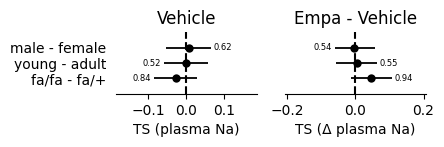

In [5]:
fig, axes = plot_effects(overall_ts_vehicle, overall_ts_change, figsize=(4, 0.8))
# fig.suptitle("Plasma Na: overall effects", y=1.12)
fig.savefig(PLOT_DIR / "ts_plasma_na_overall.pdf", bbox_inches="tight")

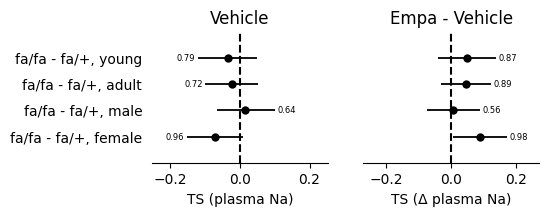

In [6]:
fig, axes = plot_effects(gtyp_ts_vehicle, gtyp_ts_change, figsize=(5, 1.7))
# fig.suptitle("Plasma Na: genotype effects by sex / age", y=1.1)
# fig.savefig(PLOT_DIR / "ts_plasma_na_gtyp_given_sex_age.pdf", bbox_inches="tight")

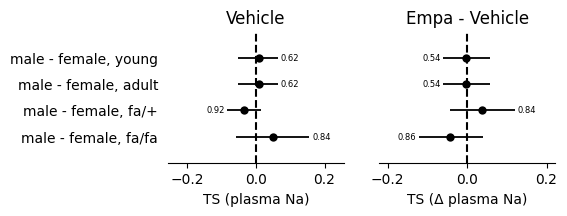

In [7]:
fig, axes = plot_effects(sex_ts_vehicle, sex_ts_change, figsize=(5, 1.7))
# fig.suptitle("Plasma Na: sex effects by genotype / age", y=1.1)
# fig.savefig(PLOT_DIR / "ts_plasma_na_sex_given_gtyp_age.pdf", bbox_inches="tight")

## Posterior sign probabilities and significance

In [8]:
def sign_prob_table(ts_vehicle, ts_change):
    sp_vehicle = get_sign_probs(ts_vehicle)
    sp_change = get_sign_probs(ts_change)
    return pd.DataFrame({
        "vehicle": sp_vehicle,
        "vehicle_signif": {k: get_signif(v) for k, v in sp_vehicle.items()},
        "empa - vehicle": sp_change,
        "empa - vehicle_signif": {k: get_signif(v) for k, v in sp_change.items()},
    })

sp_all = pd.concat(
    [
        sign_prob_table(overall_ts_vehicle, overall_ts_change),
        # sign_prob_table(gtyp_ts_vehicle, gtyp_ts_change),
        # sign_prob_table(sex_ts_vehicle, sex_ts_change),
    ],
    keys=("overall", 
          # "gtyp given sex/age", "sex given gtyp/age"
         ),
    names=("contrast", "group"),
)
display(sp_all)
# sp_all.to_csv("../sp_tables/" + "plasma_na_overall_contrasts.csv")

vehicle vehicle_signif  empa - vehicle  \
contrast group                                                   
overall  fa/fa - fa/+   0.16125                        0.94225   
         young - adult  0.47525                        0.55100   
         male - female  0.61550                        0.45700   

                       empa - vehicle_signif  
contrast group                                
overall  fa/fa - fa/+                         
         young - adult                        
         male - female

## Empa − Vehicle: change in the modeled quantity by genotype

These are **absolute modeled changes**, not genotype contrasts. Each genotype-specific estimate is averaged equally over both ages and sexes; the overall estimate is averaged equally over all eight groups. The random rat intercept is set to zero.

In [9]:
from kidney.contrasts import GTYPS, SEXES, AGES

# get_t_groups() returns group effects relative to the reference group;
# add the intercept to recover the modeled change (Empa - Vehicle).
change_group_means = {
    key: idata_change.posterior["Intercept"] + effect
    for key, effect in t_groups_change.items()
}

def mean_draws(arrays):
    return sum(arrays) / len(arrays)

change_by_genotype = {
    f"{gtyp}": mean_draws([
        change_group_means[f"{gtyp},{sex},{age}"]
        for sex in SEXES for age in AGES
    ])
    for gtyp in GTYPS
}
# change_by_genotype["Empa - Vehicle, overall"] = mean_draws(
#     list(change_group_means.values())
# )

(-0.05, 0.25)

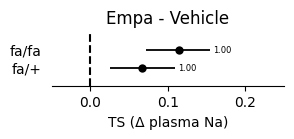

In [13]:
fig, ax = plt.subplots(figsize=(3, 0.7))
forestplot_oz(ax, change_by_genotype, xlabel="TS (\u0394 plasma Na)", sign_probs=True)
ax.set_title("Empa - Vehicle")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_xlim(-0.05, 0.25)
fig.savefig(PLOT_DIR / "ts_excretion_na_change_by_genotype.pdf", bbox_inches="tight")

In [14]:
change_sign_probs = get_sign_probs(change_by_genotype)
change_significance = pd.DataFrame({
    "sign_probability": change_sign_probs,
    "significance": {k: get_signif(v) for k, v in change_sign_probs.items()},
})
display(change_significance)

,sign_probability,significance
fa/+,0.99875,*
fa/fa,1.00000,*
